# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024160079          # <-- your full roll number
NAME = "Utkarsh Choudhary"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

In [2]:
pip install matplotlib

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160079   Name: Utkarsh Choudhary   Fingerprint: 6B3F3D28   Tickets: 16

Ticket_ID                                                                                Ticket_Text
      T01                              Password failed to open since yesterday. It worked yesterday.
      T02                  Laptop was working yesterday before the assignment deadline. Please help.
      T03                    Server is running slowly when I use mobile hotspot. Can you check this?
      T04                            Student portal crashes while opening on my laptop. Please help.
      T05 I was locked out of the printer after restarting the system. It works on another computer.
      T06                                       The VPN keeps asking for login. It worked yesterday.
      T07                              Python stopped responding since yesterday. Please resolve it.
      T08                                                         Dr. Rao's lab PC (No. 14) is down.
  

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
rows = []
all_tokens_corpus = []
all_final_corpus = []

for _, row in df.iterrows():
    res = process_ticket(row["Ticket_Text"])
    all_tokens_corpus.extend(res["tokens"])
    all_final_corpus.extend(res["final"])
    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(res["sentences"]),
        "Tokens": len(res["tokens"]),
        "Punctuation": len(res["punct"]),
        "Stopwords": len(res["stops"]),
        "Unique_Tokens": len(set(res["tokens"])),
        "Final_Tokens": len(res["final"])
    })

q1_df = pd.DataFrame(rows)

total_row = pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "Sentences": q1_df["Sentences"].sum(),
    "Tokens": q1_df["Tokens"].sum(),
    "Punctuation": q1_df["Punctuation"].sum(),
    "Stopwords": q1_df["Stopwords"].sum(),
    "Unique_Tokens": len(set(all_tokens_corpus)),
    "Final_Tokens": q1_df["Final_Tokens"].sum()
}])

q1_table = pd.concat([q1_df, total_row], ignore_index=True)
print(q1_table.to_string(index=False))

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      11            2          2              9             7
      T02          2      12            2          3             11             7
      T03          2      15            2          6             15             7
      T04          2      12            2          3             11             7
      T05          2      18            2          9             16             7
      T06          2      11            2          3             10             6
      T07          2      10            2          1              9             7
      T08          2      13            4          3             12             6
      T09          2      17            2          6             16             9
      T10          2       9            2          0              8             7
      T11          2      14            2          6             14             6
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* ca, n't, and 's

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [8]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

EMAIL_PAT = r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b'
URL_PAT   = r'(?:https?://|www\.)[^\s;,]+'
PHONE_PAT = r'(?:\+91[\s-]?)?(?:\d{5}[\s-]\d{5}|\d{4}-\d{3}-\d{4})'
NUMBER_PAT = r'\b(?:0x[0-9a-fA-F]+|\d+(?:[.,]\d+)*)\b'

print("VERIFYING RE.SUB ON TEST_LINES:")
for i, line in enumerate(TEST_LINES, 1):
    subbed = re.sub(EMAIL_PAT, "<EMAIL>", line)
    subbed = re.sub(URL_PAT, "<URL>", subbed)
    subbed = re.sub(PHONE_PAT, "<PHONE>", subbed)
    print(f"Test Line {i}:\n  {subbed}\n")

raw_corpus = " ".join(df["Ticket_Text"].tolist())

words_gt_5 = sorted(list(set(re.findall(r'\b[a-zA-Z]{6,}\b', raw_corpus))))

numbers_extracted = sorted(list(set(re.findall(NUMBER_PAT, raw_corpus))))

capitalized_words = sorted(list(set(re.findall(r'\b[A-Z][a-zA-Z]*\b', raw_corpus))))

vowel_words = sorted(list(set(re.findall(r'\b[aeiouAEIOU][a-zA-Z]*\b', raw_corpus))))

print("EXTRACTIONS ON RAW TICKETS:")
print(f"1. Words > 5 letters ({len(words_gt_5)} unique): {words_gt_5[:12]} ...")
print(f"2. Numbers extracted ({len(numbers_extracted)} unique): {numbers_extracted}")
print(f"3. Capitalized words ({len(capitalized_words)} unique): {capitalized_words}")
print(f"4. Words starting with a vowel ({len(vowel_words)} unique): {vowel_words[:12]} ...\n")

df["Masked_Ticket"] = df["Ticket_Text"].apply(
    lambda text: re.sub(PHONE_PAT, "<PHONE>", re.sub(URL_PAT, "<URL>", re.sub(EMAIL_PAT, "<EMAIL>", text)))
)

masked_subset = df[df["Masked_Ticket"] != df["Ticket_Text"]][["Ticket_ID", "Ticket_Text", "Masked_Ticket"]]
print("TICKETS MODIFIED BY RE.SUB:")
print(masked_subset.to_string(index=False) if len(masked_subset) > 0 else "No masked entities present in these tickets.")

VERIFYING RE.SUB ON TEST_LINES:
Test Line 1:
  Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Test Line 2:
  Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Test Line 3:
  The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

EXTRACTIONS ON RAW TICKETS:
1. Words > 5 letters (45 unique): ['Laptop', 'Password', 'Please', 'Printer', 'Python', 'Server', 'Student', 'access', 'another', 'asking', 'assignment', 'before'] ...
2. Numbers extracted (8 unique): ['0175', '14', '239', '3201', '43210', '91', '95.5', '98765']
3. Capitalized words (19 unique): ['Call', 'Can', 'Dr', 'Fi', 'I', 'It', 'Laptop', 'No', 'PC', 'Password', 'Please', 'Printer', 'Python', 'Rao', 'Server', 'Student', 'The', 'VPN', 'Wi']
4. Words starting with a vowel (21 unique): ['I', 'It', 'access', 'after', 'am', 'another', 'asking', 'assignment', 'email', 'is', 'it', 'of'] ...

TICKETS MODIFIED BY RE.SUB:
Ticket_ID                                  Ticket_Text                  Ma

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 9 words (Call, Can, It, Laptop, Password, Please, Printer, Student, The).

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [9]:
from nltk.tokenize import RegexpTokenizer

custom_pattern = r'''(?x)
    (?:https?://|www\.)[^\s;,]+                             # URLs
    | [A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}       # Emails
    | (?:\+91[\s-]?)?(?:\d{5}[\s-]\d{5}|\d{4}-\d{3}-\d{4})   # Phone numbers
    | \b\d+(?:\.\d+)+(?:%|\b)                                # Decimals & version numbers (e.g., 95.5%, 2.0.1)
    | \b\d{1,3}(?:,\d{3})+\b                                 # Comma formatted integers (e.g., 1,250)
    | \b[A-Za-z0-9]+(?:-[A-Za-z0-9]+)+\b                    # Hyphenated words (e.g., Wi-Fi, state-of-the-art)
    | \b[A-Za-z]+'[A-Za-z]+\b                                # Contractions (e.g., isn't, didn't, Rao's)
    | \b[A-Za-z]+\b                                          # Regular words
    | \b\d+\b                                                # Standalone digits
    | [^\s\w]                                                # Punctuation / symbols
'''

custom_tokenizer = RegexpTokenizer(custom_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("COMPARISON ON TEST_LINES:")
for i, line in enumerate(TEST_LINES, 1):
    print(f"\n--- Line {i} ---")
    print("my_tokenize   :", my_tokenize(line))
    print("word_tokenize :", word_tokenize(line))

print("\nCOMPARISON ON GENERATED TICKETS:")
diff_tickets = []
for _, row in df.iterrows():
    t_my = my_tokenize(row["Ticket_Text"])
    t_word = word_tokenize(row["Ticket_Text"])
    if t_my != t_word:
        diff_tickets.append((row["Ticket_ID"], row["Ticket_Text"], t_my, t_word))

print(f"Total tickets: {len(df)}")
print(f"Tickets tokenized differently: {len(diff_tickets)} out of {len(df)} ({len(diff_tickets) / len(df) * 100:.1f}%)")

if diff_tickets:
    tid, text, t_my, t_word = diff_tickets[0]
    print(f"\nExample Difference ({tid}):")
    print("Original Text :", text)
    print("my_tokenize   :", t_my)
    print("word_tokenize :", t_word)

COMPARISON ON TEST_LINES:

--- Line 1 ---
my_tokenize   : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize : ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

--- Line 2 ---
my_tokenize   : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize : ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

--- Line 3 ---
my_tokenize   : ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize : ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 6 out of 16 tickets (37.5%)

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [10]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

unique_final_words = sorted(list(set(all_final_corpus)))

porter = PorterStemmer()
lancaster = LancasterStemmer()

regexp_stemmer = RegexpStemmer(r'(ing|ed|es|s|ly)$', min=4)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(treebank_tag):
    """Map POS tag to first character recognized by wordnet.lemmatize()"""
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

tagged_words = nltk.pos_tag(unique_final_words)

records = []
for word, tag in tagged_words:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp_stemmer.stem(word)
    wn_pos = get_wordnet_pos(tag)
    w_lemma = lemmatizer.lemmatize(word, pos=wn_pos)


    if not (p_stem == l_stem == r_stem == w_lemma):
        records.append({
            "Word": word,
            "POS_Tag": tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp": r_stem,
            "Lemmatizer": w_lemma
        })

diff_df = pd.DataFrame(records)
print(f"Total Unique Final Tokens: {len(unique_final_words)}")
print(f"Words with Differing Stem/Lemma Outputs: {len(diff_df)}\n")
print(diff_df.to_string(index=False))

Total Unique Final Tokens: 67
Words with Differing Stem/Lemma Outputs: 30

      Word POS_Tag  Porter Lancaster     Regexp Lemmatizer
    access      NN  access    access      acces     access
   another      DT   anoth     anoth    another    another
assignment      NN  assign    assign assignment assignment
      call      VB    call       cal       call       call
    campus      NN   campu      camp      campu     campus
  computer      NN  comput    comput   computer   computer
  deadline      VB deadlin   deadlin   deadline   deadline
      file      NN    file       fil       file       file
    latest     JJS  latest    latest     latest       late
    mobile     VBP   mobil      mobl     mobile     mobile
      open      JJ    open        op       open       open
   opening     VBG    open        op       open       open
    please      NN   pleas     pleas     please     please
    portal      JJ  portal      port     portal     portal
   printer      NN printer     print    

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: student to stud (by Lancaster) or campus to camp (by Lancaster).   
Under-stemming: update to update (by Regexp) or tried to tri (by Porter/Lancaster vs lemma try).   

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS(TTR)
               Stage  Total Tokens (N)  Unique Tokens (V)  TTR (V/N)
     S1 (All tokens)               203                102     0.5025
 S2 (No punctuation)               170                 95     0.5588
   S3 (Final tokens)               103                 67     0.6505
S4 (S3 after Porter)               103                 64     0.6214
Top 10 Words in S1 (All Tokens):
  .               : 25
  the             : 12
  yesterday       : 7
  i               : 7
  it              : 5
  please          : 4
  on              : 4
  password        : 3
  to              : 3
  since           : 3

Top 10 Words in S3 (Final Tokens):
  yesterday       : 7
  please          : 4
  password        : 3
  since           : 3
  laptop          : 3
  help            : 3
  works           : 3
  open            : 2
  worked          : 2
  working         : 2
Top 5 Bigrams in S1:
  ('yesterday', '.')             : 5
  ('.', 'it')                    : 4
  ('.', 'please')         

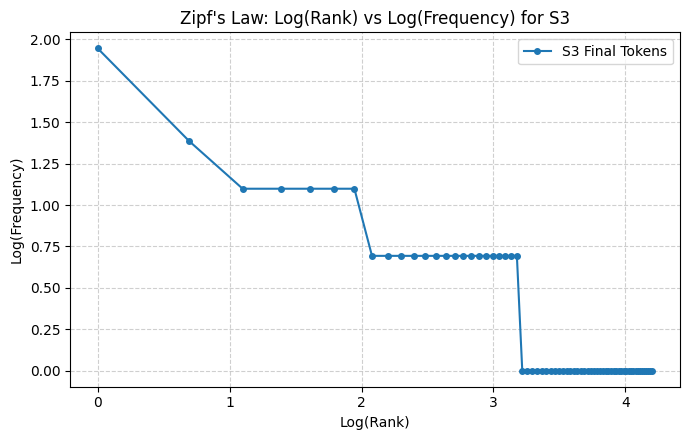

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Define Corpus Stages S1, S2, S3, S4
S1 = all_tokens_corpus
S2 = [t for t in S1 if not is_punct(t)]
S3 = all_final_corpus
S4 = [porter.stem(t) for t in S3]

stages = {
    "S1 (All tokens)": S1,
    "S2 (No punctuation)": S2,
    "S3 (Final tokens)": S3,
    "S4 (S3 after Porter)": S4
}

# 1. Corpus Statistics Table
stats = []
for name, tokens in stages.items():
    n = len(tokens)
    v = len(set(tokens))
    ttr = v / n if n > 0 else 0
    stats.append({
        "Stage": name,
        "Total Tokens (N)": n,
        "Unique Tokens (V)": v,
        "TTR (V/N)": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)
print("CORPUS STATISTICS(TTR)")
print(stats_df.to_string(index=False))


# 2. Top 10 Words in S1 and S3
top10_s1 = Counter(S1).most_common(10)
top10_s3 = Counter(S3).most_common(10)

print("Top 10 Words in S1 (All Tokens):")
for w, c in top10_s1:
    print(f"  {w:<15} : {c}")

print("\nTop 10 Words in S3 (Final Tokens):")
for w, c in top10_s3:
    print(f"  {w:<15} : {c}")


# 3. Top 5 Bigrams in S1 and S3
bigrams_s1 = list(nltk.bigrams(S1))
bigrams_s3 = list(nltk.bigrams(S3))

print("Top 5 Bigrams in S1:")
for bg, c in Counter(bigrams_s1).most_common(5):
    print(f"  {str(bg):<30} : {c}")

print("\nTop 5 Bigrams in S3:")
for bg, c in Counter(bigrams_s3).most_common(5):
    print(f"  {str(bg):<30} : {c}")

# 4. Plot Log(Rank) vs Log(Frequency) for S3 (Zipf's Law)
freqs_s3 = sorted(Counter(S3).values(), reverse=True)
ranks_s3 = list(range(1, len(freqs_s3) + 1))

log_ranks = np.log(ranks_s3)
log_freqs = np.log(freqs_s3)

plt.figure(figsize=(7, 4.5))
plt.plot(log_ranks, log_freqs, marker='o', markersize=4, linestyle='-', color='#1f77b4', label='S3 Final Tokens')
plt.title("Zipf's Law: Log(Rank) vs Log(Frequency) for S3")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* S1 to S3 (0.5025 to 0.6505): TTR increases because removing frequent, repetitive punctuation and common stopwords reduces the total token count (N), while removing relatively few unique tokens (V).   
S3 to S4 (0.6505 to 0.6214): TTR decreases because stemming conflates inflectional variants (e.g., worked, working, and works to work) into single base forms, which reduces the number of unique vocabulary words (V) while keeping total tokens (N) constant. 